# Estudio 1 — Los parámetros de los papers

**Pregunta:** si usamos los parámetros de Couzin (2002) y Puckett et al. (2018), ¿nuestros peces se comportan como dicen los papers?

El plan completo está en el [README](README.md). Este cuaderno tiene tres partes:

- **A:** una escalera que va de nuestro modelo (A0) al de Puckett (A4), agregando una cosa a la vez;
- **B:** el modelo de Puckett con 16, 32 y 64 peces y velocidades de 0.2 a 5 BL/s;
- **C:** el diagrama de Couzin (cambiar la zona de orientación) y la "memoria colectiva".

Las simulaciones se guardan en `data/`. Si el CSV ya existe, se carga y no se vuelve a simular.

## Preparación

Cargamos las herramientas comunes (`study_tools.py`) y definimos las carpetas y las 10 seeds (0–9).

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the checks folder (the one with study_code/study_tools.py) and let Python import from study_code.
CHECKS_FOLDER = Path.cwd()
while not (CHECKS_FOLDER / "study_code" / "study_tools.py").is_file():
    if CHECKS_FOLDER == CHECKS_FOLDER.parent:
        raise FileNotFoundError("study_code/study_tools.py was not found in this folder or any parent folder.")
    CHECKS_FOLDER = CHECKS_FOLDER.parent
TOOLS_FOLDER = CHECKS_FOLDER / "study_code"
if str(TOOLS_FOLDER) not in sys.path:
    sys.path.insert(0, str(TOOLS_FOLDER))

import study_tools
from study_tools import (
    A0_SETTINGS, PUCKETT_SETTINGS, A0_COLOR, PUCKETT_COLOR, EXTRA_COLOR,
    build_model, change_settings, final_label_counts, measure_moment,
    run_many, short_table, summarize,
)

# Where this study keeps its results and figures.
STUDY_FOLDER = CHECKS_FOLDER / "trial_four_paper_parameters"
DATA_FOLDER = STUDY_FOLDER / "data"
FIGURE_FOLDER = STUDY_FOLDER / "figures"
DATA_FOLDER.mkdir(exist_ok=True)
FIGURE_FOLDER.mkdir(exist_ok=True)

SEEDS = list(range(10))
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

## La definición de "funciona" (fijada antes de correr)

Estos umbrales están en `study_tools.py` y **no se cambian después de ver los resultados**. Un cardumen funciona si, en el último tercio de la simulación:

1. el grupo más grande tiene al menos el 95 % de los peces durante al menos el 90 % del tiempo (dos peces están conectados si están dentro del radio de atracción);
2. como máximo el 5 % del tiempo hay algún par de peces a menos de 0.25 BL;
3. la polarización media o la rotación media es al menos 0.65.

In [2]:
# Print the fixed thresholds, so they are visible in the executed notebook.
print("Swim distance per run:", study_tools.SWIM_DISTANCE, "BL")
print("Together: largest group >=", study_tools.TOGETHER_FRACTION, "of the fish, during >=", study_tools.TOGETHER_TIME, "of the window")
print("Collision: a pair closer than", study_tools.COLLISION_DISTANCE, "BL, allowed in <=", study_tools.COLLISION_TIME, "of the window")
print("Ordered: mean polarization or mean rotation >=", study_tools.ORDER_THRESHOLD)

Swim distance per run: 180.0 BL
Together: largest group >= 0.95 of the fish, during >= 0.9 of the window
Collision: a pair closer than 0.25 BL, allowed in <= 0.05 of the window
Ordered: mean polarization or mean rotation >= 0.65


## Parte A — La escalera: de nuestro modelo al de Puckett

Agregamos **una cosa a la vez**: campo visual de 270°, giro máximo de 1.75 rad por decisión, ruido de 0.01 rad por decisión y arena de 28 × 28 BL. Siempre con 20 peces, 1 BL/s y dt = 0.125 s.

In [3]:
# Each step of the ladder is the previous step plus one change.
ladder = []
ladder.append(change_settings(A0_SETTINGS, "A0: nuestro modelo", {}))
ladder.append(change_settings(ladder[-1], "A1: + visión 270°", {"fov_degrees": 270.0}))
ladder.append(change_settings(ladder[-1], "A2: + giro máx. 1.75 rad", {"turn_per_decision": 1.75}))
ladder.append(change_settings(ladder[-1], "A3: + ruido 0.01 rad", {"noise_per_decision": 0.01}))
ladder.append(change_settings(ladder[-1], "A4: + arena 28 BL (Puckett)", {"arena": 28.0}))

# The last step must be exactly the Puckett configuration from study_tools.py.
for key in PUCKETT_SETTINGS:
    if key not in ["label", "base"]:
        assert ladder[-1][key] == PUCKETT_SETTINGS[key], key

for settings in ladder:
    print(settings["label"])

A0: nuestro modelo
A1: + visión 270°
A2: + giro máx. 1.75 rad
A3: + ruido 0.01 rad
A4: + arena 28 BL (Puckett)


Corremos las 5 configuraciones con las 10 seeds (50 simulaciones).

In [4]:
ladder_results = run_many(ladder, SEEDS, DATA_FOLDER / "part_a_ladder.csv")
ladder_summary = summarize(ladder_results, "label")

Loaded saved results from part_a_ladder.csv (set study_tools.RERUN = True to simulate again).


### Resultados de la escalera

Media ± error estándar entre las 10 seeds. "works" = en cuántas seeds funciona el cardumen. "NND" = distancia media al vecino más cercano.

In [5]:
short_table(ladder_summary)

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,A0: nuestro modelo,10/10,0.95 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.00
1,A1: + visión 270°,10/10,0.97 ± 0.00,0.02 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
2,A2: + giro máx. 1.75 rad,10/10,0.96 ± 0.01,0.04 ± 0.01,0.62 ± 0.04,0.99 ± 0.01,0.00 ± 0.00,0.26 ± 0.01
3,A3: + ruido 0.01 rad,9/10,0.96 ± 0.01,0.04 ± 0.01,0.60 ± 0.02,0.99 ± 0.01,0.00 ± 0.00,0.27 ± 0.01
4,A4: + arena 28 BL (Puckett),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01


En qué estado termina cada seed (según las medias del último tercio):

In [6]:
final_label_counts(ladder_results)

label_final,polarized,milling,swarm,fragmented
label,,,,
A0: nuestro modelo,10,0,0,0
A1: + visión 270°,10,0,0,0
A2: + giro máx. 1.75 rad,10,0,0,0
A3: + ruido 0.01 rad,9,0,0,1
A4: + arena 28 BL (Puckett),6,0,0,4


### Figura A

Polarización, distancia al vecino y tiempo juntos en cada paso de la escalera (media ± error estándar).

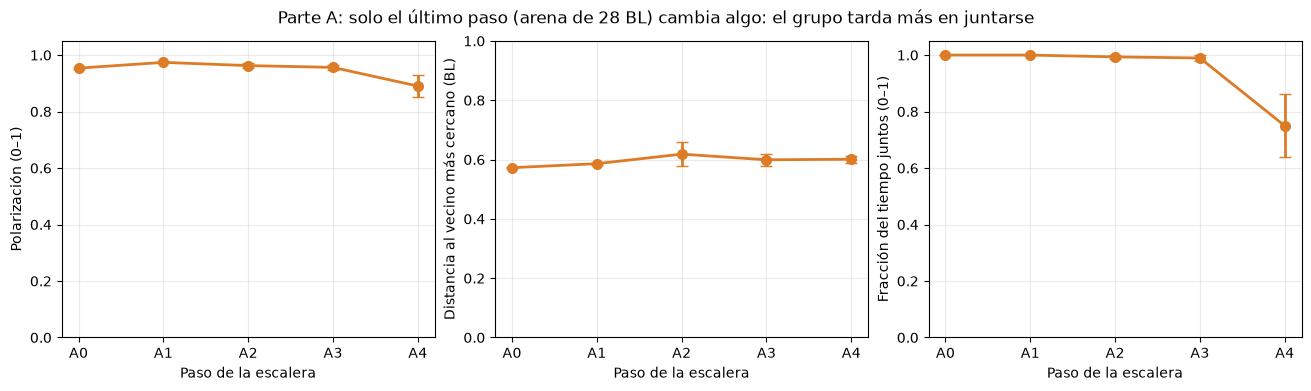

In [7]:
FIGURE_A_TITLE = "Parte A: solo el último paso (arena de 28 BL) cambia algo: el grupo tarda más en juntarse"

steps = list(range(len(ladder_summary)))
step_names = ["A0", "A1", "A2", "A3", "A4"]
panels = [
    ("polarization", "Polarización (0–1)"),
    ("nnd", "Distancia al vecino más cercano (BL)"),
    ("together_fraction", "Fracción del tiempo juntos (0–1)"),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for axis, (column, axis_label) in zip(axes, panels):
    axis.errorbar(steps, ladder_summary[column], yerr=ladder_summary[column + "_se"],
                  color=PUCKETT_COLOR, marker="o", markersize=7, linewidth=2, capsize=4)
    axis.set_xticks(steps)
    axis.set_xticklabels(step_names)
    axis.set_xlabel("Paso de la escalera")
    axis.set_ylabel(axis_label)
    axis.grid(alpha=0.25)
axes[0].set_ylim(0, 1.05)
axes[1].set_ylim(0, 1.0)
axes[2].set_ylim(0, 1.05)
fig.suptitle(FIGURE_A_TITLE)
fig.savefig(FIGURE_FOLDER / "part_a_ladder.png", dpi=150)
plt.show()

## Parte B — El modelo de Puckett con distintos grupos y velocidades

Configuración A4 con N = 16, 32 y 64 peces (los tamaños de los experimentos de Puckett) y velocidad 0.2, 1, 2.6 y 5 BL/s (el rango que va a tener la luz). Cada corrida dura hasta que cada pez nadó 180 BL, así que a 0.2 BL/s son 7200 decisiones y a 5 BL/s son 288.

In [8]:
GROUP_SIZES = [16, 32, 64]
SPEEDS = [0.2, 1.0, 2.6, 5.0]

groups_and_speeds = []
for n_fish in GROUP_SIZES:
    for speed in SPEEDS:
        label = f"N={n_fish}, v={speed:g}"
        groups_and_speeds.append(change_settings(PUCKETT_SETTINGS, label, {"n_fish": n_fish, "speed": speed}))

print(len(groups_and_speeds), "configurations")

12 configurations


Corremos las 12 combinaciones con 10 seeds (120 simulaciones; las de 64 peces a 0.2 BL/s son las más lentas, unos 40 s cada una).

In [9]:
groups_results = run_many(groups_and_speeds, SEEDS, DATA_FOLDER / "part_b_groups_speeds.csv")
groups_summary = summarize(groups_results, ["label", "n_fish", "speed", "step_length"])

Loaded saved results from part_b_groups_speeds.csv (set study_tools.RERUN = True to simulate again).


### Resultados de la parte B

In [10]:
table_b = short_table(groups_summary)
table_b.insert(1, "step length ℓ (BL)", groups_summary["step_length"])
table_b

,configuration,step length ℓ (BL),works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"N=16, v=0.2",0.025,6/10,0.91 ± 0.04,0.13 ± 0.07,0.59 ± 0.04,0.81 ± 0.10,0.00 ± 0.00,0.47 ± 0.00
1,"N=16, v=1",0.125,8/10,0.91 ± 0.06,0.13 ± 0.08,0.67 ± 0.08,0.84 ± 0.11,0.00 ± 0.00,0.30 ± 0.01
2,"N=16, v=2.6",0.325,3/10,0.87 ± 0.06,0.15 ± 0.07,0.72 ± 0.03,0.78 ± 0.12,0.05 ± 0.00,0.07 ± 0.01
3,"N=16, v=5",0.625,0/10,0.73 ± 0.03,0.28 ± 0.06,1.11 ± 0.13,0.43 ± 0.13,0.16 ± 0.02,0.04 ± 0.00
4,"N=32, v=0.2",0.025,8/10,0.92 ± 0.05,0.12 ± 0.07,0.56 ± 0.04,0.88 ± 0.10,0.00 ± 0.00,0.45 ± 0.00
5,"N=32, v=1",0.125,8/10,0.85 ± 0.01,0.08 ± 0.02,0.57 ± 0.02,0.94 ± 0.04,0.00 ± 0.00,0.23 ± 0.01
6,"N=32, v=2.6",0.325,0/10,0.53 ± 0.02,0.15 ± 0.04,0.67 ± 0.06,0.81 ± 0.11,0.75 ± 0.08,0.01 ± 0.00
7,"N=32, v=5",0.625,0/10,0.32 ± 0.01,0.10 ± 0.01,0.95 ± 0.10,0.50 ± 0.12,0.91 ± 0.02,0.01 ± 0.00
8,"N=64, v=0.2",0.025,0/10,0.13 ± 0.00,0.06 ± 0.00,0.49 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.40 ± 0.00
9,"N=64, v=1",0.125,0/10,0.11 ± 0.00,0.05 ± 0.00,0.42 ± 0.00,1.00 ± 0.00,0.39 ± 0.01,0.03 ± 0.00


In [11]:
final_label_counts(groups_results)

label_final,polarized,milling,swarm,fragmented
label,,,,
"N=16, v=0.2",6,0,0,4
"N=16, v=1",8,0,0,2
"N=16, v=2.6",7,0,0,3
"N=16, v=5",3,0,0,7
"N=32, v=0.2",8,0,0,2
"N=32, v=1",8,0,0,2
"N=32, v=2.6",0,0,7,3
"N=32, v=5",0,0,3,7
"N=64, v=0.2",0,0,10,0


### Figura B

Cada línea es un tamaño de grupo. El eje x es la velocidad; arriba se indica también el largo de paso ℓ = velocidad × 0.125 s.

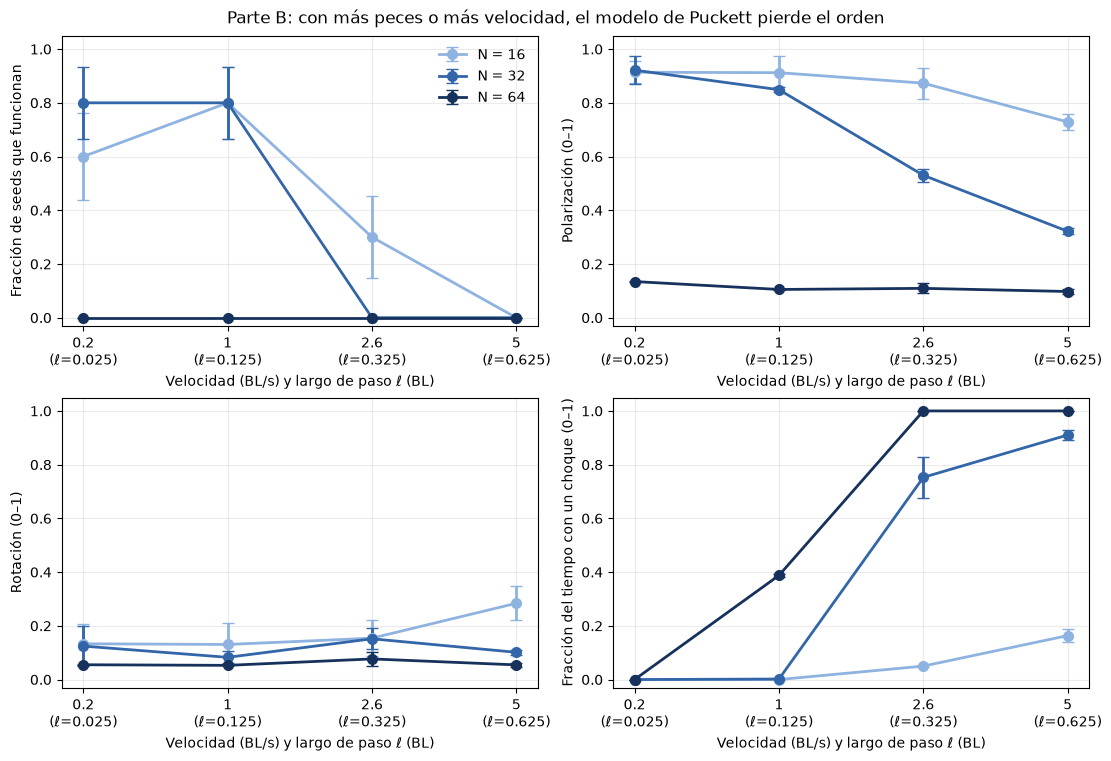

In [12]:
FIGURE_B_TITLE = "Parte B: con más peces o más velocidad, el modelo de Puckett pierde el orden"

# Darker blue = bigger group (N is a magnitude, so one hue from light to dark).
GROUP_COLORS = {16: "#8fb3e0", 32: "#3366a8", 64: "#16325c"}
panels = [
    ("works", "Fracción de seeds que funcionan"),
    ("polarization", "Polarización (0–1)"),
    ("rotation", "Rotación (0–1)"),
    ("collision_fraction", "Fracción del tiempo con un choque (0–1)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), constrained_layout=True)
for axis, (column, axis_label) in zip(axes.flat, panels):
    # The four speeds are drawn at equal distances (positions 0, 1, 2, 3).
    positions = list(range(len(SPEEDS)))
    for n_fish in GROUP_SIZES:
        rows = groups_summary[groups_summary["n_fish"] == n_fish]
        axis.errorbar(positions, rows[column], yerr=rows[column + "_se"], color=GROUP_COLORS[n_fish],
                      marker="o", markersize=7, linewidth=2, capsize=4, label=f"N = {n_fish}")
    tick_texts = []
    for speed in SPEEDS:
        tick_texts.append(f"{speed:g}\n(ℓ={speed * 0.125:g})")
    axis.set_xticks(positions)
    axis.set_xticklabels(tick_texts)
    axis.set_xlabel("Velocidad (BL/s) y largo de paso ℓ (BL)")
    axis.set_ylabel(axis_label)
    axis.set_ylim(-0.03, 1.05)
    axis.grid(alpha=0.25)
axes[0, 0].legend(frameon=False)
fig.suptitle(FIGURE_B_TITLE)
fig.savefig(FIGURE_FOLDER / "part_b_groups_speeds.png", dpi=150)
plt.show()

## Parte C — El diagrama de Couzin

Couzin (2002) encontró que, al agrandar la zona de orientación, el grupo pasa de **swarm** a **torus** (milling) y después a **grupo paralelo**. Usamos la configuración A4 con r_r = 0.5 BL y r_a = 7 BL fijos, y movemos r_o entre 0.55 y 7 BL.

En Couzin r_r = 1 "unidad" = 0.5 BL nuestros. Su paso a torus (r_o ≈ 1.5 unidades) corresponde a r_o ≈ 0.75 BL, y su paso a grupo polarizado (r_o > 2.5 unidades) a r_o > 1.25 BL. **Ojo:** el modelo de Couzin es 3D y gira como máximo 4° por decisión (40°/s con dt = 0.1 s); Puckett gira hasta 100° (1.75 rad).

In [13]:
ORIENTATION_RADII = [0.55, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]

couzin_diagram = []
for orientation_radius in ORIENTATION_RADII:
    label = f"r_o={orientation_radius:g}"
    changes = {"orientation_radius": orientation_radius, "attraction_radius": 7.0}
    couzin_diagram.append(change_settings(PUCKETT_SETTINGS, label, changes))

Corremos los 10 valores de r_o con 10 seeds (100 simulaciones).

In [14]:
couzin_results = run_many(couzin_diagram, SEEDS, DATA_FOLDER / "part_c_couzin.csv")
couzin_summary = summarize(couzin_results, ["label", "orientation_radius"])

Loaded saved results from part_c_couzin.csv (set study_tools.RERUN = True to simulate again).


### Resultados de la parte C

Con r_a = 7 BL, "juntos" usa un enlace de 7 BL. La columna `together (5.5 BL link)` repite la cuenta con el enlace fijo de 5.5 BL, para comparar con las otras partes.

In [15]:
table_c = short_table(couzin_summary)
table_c["together (5.5 BL link)"] = study_tools.mean_and_error_text(couzin_summary, "together_fraction_fixed_link")
table_c

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL),together (5.5 BL link)
0,r_o=0.55,0/10,0.18 ± 0.01,0.11 ± 0.01,1.20 ± 0.12,0.44 ± 0.11,0.05 ± 0.01,0.14 ± 0.02,0.39 ± 0.11
1,r_o=0.75,0/10,0.17 ± 0.01,0.11 ± 0.01,1.13 ± 0.07,0.66 ± 0.11,0.06 ± 0.01,0.13 ± 0.01,0.62 ± 0.11
2,r_o=1,0/10,0.21 ± 0.02,0.13 ± 0.02,1.06 ± 0.11,0.58 ± 0.14,0.05 ± 0.01,0.16 ± 0.01,0.55 ± 0.14
3,r_o=1.5,0/10,0.22 ± 0.02,0.11 ± 0.01,0.84 ± 0.11,0.85 ± 0.06,0.05 ± 0.00,0.11 ± 0.02,0.81 ± 0.07
4,r_o=2,3/10,0.57 ± 0.03,0.11 ± 0.02,0.62 ± 0.06,0.99 ± 0.01,0.01 ± 0.00,0.22 ± 0.01,0.98 ± 0.02
5,r_o=3,10/10,0.98 ± 0.00,0.02 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.30 ± 0.01,1.00 ± 0.00
6,r_o=4,6/10,0.93 ± 0.02,0.16 ± 0.07,0.63 ± 0.03,0.80 ± 0.11,0.00 ± 0.00,0.27 ± 0.01,0.80 ± 0.11
7,r_o=5,9/10,0.93 ± 0.06,0.11 ± 0.08,0.64 ± 0.03,0.90 ± 0.10,0.00 ± 0.00,0.30 ± 0.01,0.90 ± 0.10
8,r_o=6,10/10,0.99 ± 0.00,0.05 ± 0.01,0.66 ± 0.01,1.00 ± 0.00,0.00 ± 0.00,0.33 ± 0.01,1.00 ± 0.00
9,r_o=7,10/10,0.99 ± 0.00,0.06 ± 0.01,0.74 ± 0.04,1.00 ± 0.00,0.00 ± 0.00,0.31 ± 0.01,1.00 ± 0.00


In [16]:
final_label_counts(couzin_results)

label_final,polarized,milling,swarm,fragmented
label,,,,
r_o=0.55,0,0,2,8
r_o=0.75,0,0,4,6
r_o=1,0,0,4,6
r_o=1.5,0,0,5,5
r_o=2,3,0,6,1
r_o=3,10,0,0,0
r_o=4,6,0,0,4
r_o=5,9,0,0,1
r_o=6,10,0,0,0


### Figura C1 — Polarización y rotación en función de r_o

Las líneas grises punteadas marcan dónde Couzin vio el paso a torus (0.75 BL) y a grupo polarizado (1.25 BL), traducidos a nuestras unidades.

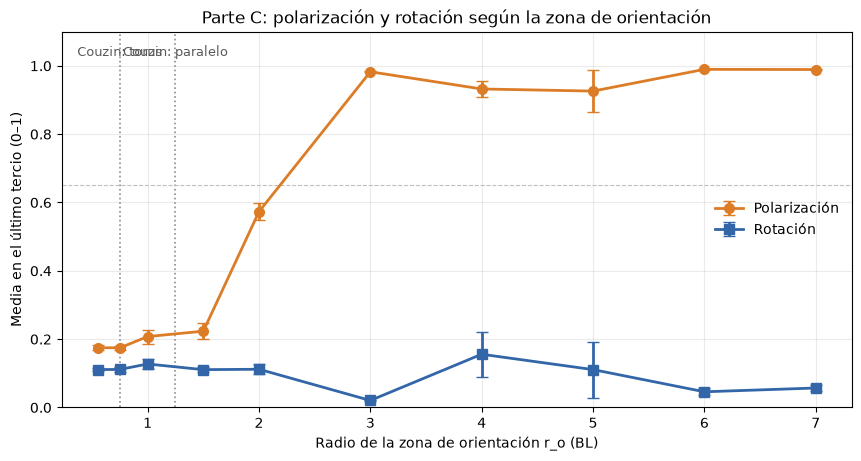

In [17]:
FIGURE_C1_TITLE = "Parte C: polarización y rotación según la zona de orientación"

fig, axis = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
axis.errorbar(couzin_summary["orientation_radius"], couzin_summary["polarization"],
              yerr=couzin_summary["polarization_se"], color=PUCKETT_COLOR, marker="o",
              markersize=7, linewidth=2, capsize=4, label="Polarización")
axis.errorbar(couzin_summary["orientation_radius"], couzin_summary["rotation"],
              yerr=couzin_summary["rotation_se"], color=A0_COLOR, marker="s",
              markersize=7, linewidth=2, capsize=4, label="Rotación")
for radius, text in [(0.75, "Couzin: torus"), (1.25, "Couzin: paralelo")]:
    axis.axvline(radius, color="0.55", linestyle=":", linewidth=1.2)
    axis.text(radius, 1.02, text, ha="center", va="bottom", fontsize=9, color="0.35")
axis.axhline(0.65, color="0.75", linestyle="--", linewidth=0.8)
axis.set_xlabel("Radio de la zona de orientación r_o (BL)")
axis.set_ylabel("Media en el último tercio (0–1)")
axis.set_ylim(0, 1.1)
axis.grid(alpha=0.25)
axis.legend(frameon=False, loc="center right")
axis.set_title(FIGURE_C1_TITLE)
fig.savefig(FIGURE_FOLDER / "part_c_couzin_diagram.png", dpi=150)
plt.show()

### Figura C2 — En qué estado pasa el tiempo el grupo

Para cada r_o, la fracción del último tercio que el grupo pasa polarizado, en milling, en swarm o separado (media de las 10 seeds).

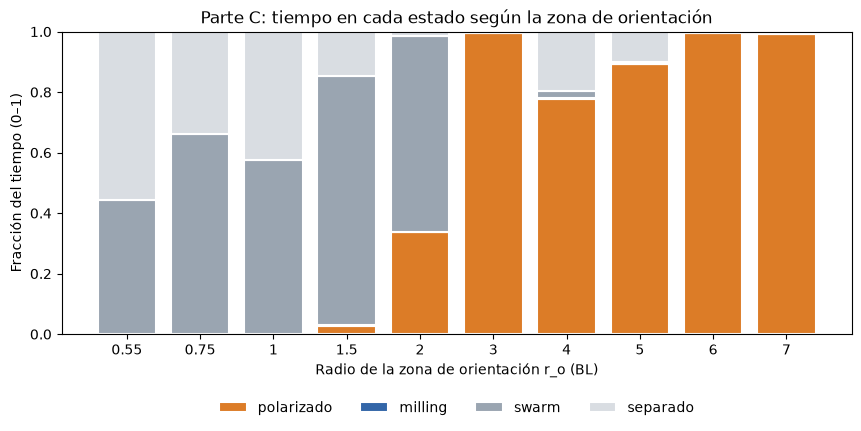

In [18]:
FIGURE_C2_TITLE = "Parte C: tiempo en cada estado según la zona de orientación"

STATE_COLORS = {"polarized": PUCKETT_COLOR, "milling": A0_COLOR, "swarm": "#9aa5b1", "fragmented": "#d9dde2"}
STATE_NAMES = {"polarized": "polarizado", "milling": "milling", "swarm": "swarm", "fragmented": "separado"}

positions = list(range(len(couzin_summary)))
bottom = np.zeros(len(couzin_summary))
fig, axis = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
for state in ["polarized", "milling", "swarm", "fragmented"]:
    values = couzin_summary["time_" + state].to_numpy()
    axis.bar(positions, values, bottom=bottom, color=STATE_COLORS[state], edgecolor="white",
             linewidth=1.5, label=STATE_NAMES[state])
    bottom = bottom + values
axis.set_xticks(positions)
axis.set_xticklabels([f"{radius:g}" for radius in couzin_summary["orientation_radius"]])
axis.set_xlabel("Radio de la zona de orientación r_o (BL)")
axis.set_ylabel("Fracción del tiempo (0–1)")
axis.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
axis.set_title(FIGURE_C2_TITLE)
fig.savefig(FIGURE_FOLDER / "part_c_states.png", dpi=150)
plt.show()

### Parte C extra (no está en el README) — ¿Y si giran despacio, como en Couzin?

Con los parámetros de Puckett no aparece el **torus** (milling). Una diferencia grande con Couzin (2002) es el giro: Couzin usa un giro máximo de 40°/s con pasos de 0.1 s, es decir **4° (0.07 rad) por decisión**; Puckett permite **1.75 rad (100°) por decisión**. Repetimos el diagrama cambiando **solo** eso: giro máximo de 0.07 rad por decisión.

In [19]:
COUZIN_TURN = 0.07   # rad per decision: 40 degrees per second x 0.1 s (Couzin 2002, Fig. 3)

slow_turn_diagram = []
for orientation_radius in ORIENTATION_RADII:
    label = f"giro lento, r_o={orientation_radius:g}"
    changes = {"orientation_radius": orientation_radius, "attraction_radius": 7.0,
               "turn_per_decision": COUZIN_TURN}
    slow_turn_diagram.append(change_settings(PUCKETT_SETTINGS, label, changes))

slow_results = run_many(slow_turn_diagram, SEEDS, DATA_FOLDER / "part_c_couzin_slow_turn.csv")
slow_summary = summarize(slow_results, ["label", "orientation_radius"])
short_table(slow_summary)

Loaded saved results from part_c_couzin_slow_turn.csv (set study_tools.RERUN = True to simulate again).


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"giro lento, r_o=0.55",0/10,0.19 ± 0.01,0.20 ± 0.03,1.07 ± 0.04,0.61 ± 0.16,0.38 ± 0.02,0.01 ± 0.00
1,"giro lento, r_o=0.75",0/10,0.17 ± 0.01,0.21 ± 0.04,1.17 ± 0.07,0.72 ± 0.14,0.34 ± 0.04,0.01 ± 0.00
2,"giro lento, r_o=1",0/10,0.21 ± 0.02,0.30 ± 0.05,1.11 ± 0.09,0.70 ± 0.15,0.34 ± 0.03,0.02 ± 0.00
3,"giro lento, r_o=1.5",0/10,0.30 ± 0.07,0.48 ± 0.07,1.12 ± 0.10,0.90 ± 0.10,0.37 ± 0.04,0.02 ± 0.00
4,"giro lento, r_o=2",0/10,0.65 ± 0.09,0.31 ± 0.09,0.67 ± 0.06,0.89 ± 0.08,0.27 ± 0.03,0.02 ± 0.00
5,"giro lento, r_o=3",0/10,0.88 ± 0.06,0.18 ± 0.09,0.56 ± 0.01,0.80 ± 0.13,0.15 ± 0.01,0.02 ± 0.00
6,"giro lento, r_o=4",0/10,0.97 ± 0.00,0.05 ± 0.01,0.61 ± 0.01,1.00 ± 0.00,0.12 ± 0.01,0.03 ± 0.00
7,"giro lento, r_o=5",0/10,0.96 ± 0.01,0.06 ± 0.01,0.65 ± 0.01,0.99 ± 0.01,0.12 ± 0.01,0.03 ± 0.00
8,"giro lento, r_o=6",0/10,0.97 ± 0.01,0.05 ± 0.01,0.66 ± 0.01,1.00 ± 0.00,0.11 ± 0.01,0.03 ± 0.01
9,"giro lento, r_o=7",2/10,0.95 ± 0.01,0.07 ± 0.01,0.74 ± 0.02,1.00 ± 0.00,0.09 ± 0.01,0.03 ± 0.01


In [20]:
final_label_counts(slow_results)

label_final,polarized,milling,swarm,fragmented
label,,,,
"giro lento, r_o=0.55",0,0,6,4
"giro lento, r_o=0.75",0,0,6,4
"giro lento, r_o=1",0,0,7,3
"giro lento, r_o=1.5",1,3,5,1
"giro lento, r_o=2",5,2,1,2
"giro lento, r_o=3",8,0,0,2
"giro lento, r_o=4",10,0,0,0
"giro lento, r_o=5",10,0,0,0
"giro lento, r_o=6",10,0,0,0


### Figura C3 — Giro rápido (Puckett) contra giro lento (Couzin)

Polarización (naranja) y rotación (azul) en función de r_o. Media ± error estándar de 10 seeds.

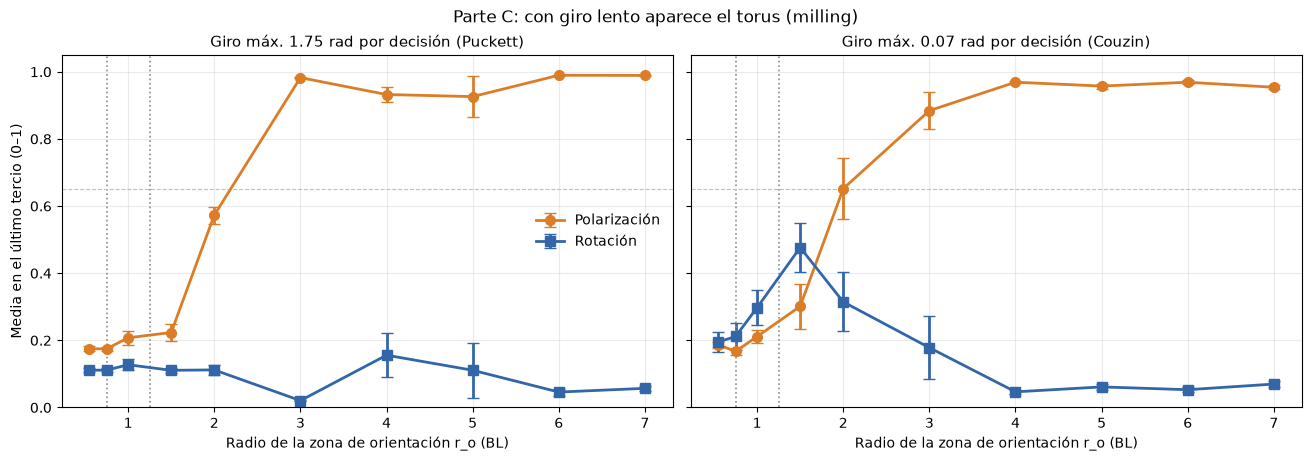

In [21]:
FIGURE_C3_TITLE = "Parte C: con giro lento aparece el torus (milling)"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, constrained_layout=True)
for axis, summary, title in [(axes[0], couzin_summary, "Giro máx. 1.75 rad por decisión (Puckett)"),
                             (axes[1], slow_summary, "Giro máx. 0.07 rad por decisión (Couzin)")]:
    axis.errorbar(summary["orientation_radius"], summary["polarization"], yerr=summary["polarization_se"],
                  color=PUCKETT_COLOR, marker="o", markersize=7, linewidth=2, capsize=4, label="Polarización")
    axis.errorbar(summary["orientation_radius"], summary["rotation"], yerr=summary["rotation_se"],
                  color=A0_COLOR, marker="s", markersize=7, linewidth=2, capsize=4, label="Rotación")
    for radius in [0.75, 1.25]:
        axis.axvline(radius, color="0.55", linestyle=":", linewidth=1.2)
    axis.axhline(0.65, color="0.75", linestyle="--", linewidth=0.8)
    axis.set_xlabel("Radio de la zona de orientación r_o (BL)")
    axis.set_title(title, fontsize=11)
    axis.set_ylim(0, 1.05)
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Media en el último tercio (0–1)")
axes[0].legend(frameon=False, loc="center right")
fig.suptitle(FIGURE_C3_TITLE)
fig.savefig(FIGURE_FOLDER / "part_c_slow_turn.png", dpi=150)
plt.show()

### Parte C (opcional) — Memoria colectiva

Como en la figura 4 de Couzin (2002): en **una sola simulación larga** subimos r_o poco a poco y después lo bajamos. Con cada valor corremos 2000 decisiones (como Couzin) y medimos el último tercio. Si el grupo "se acuerda" de dónde viene, la curva de subida y la de bajada no coinciden.

Usamos los valores de la figura de Couzin (r_o de 1 a 4.5 unidades), traducidos a BL: de 0.55 a 2.25 BL, con r_a = 7 BL. Lo hacemos con el giro de Puckett y con el giro lento de Couzin.

In [22]:
MEMORY_RADII = [0.55, 0.65, 0.75, 0.875, 1.0, 1.125, 1.25, 1.5, 1.75, 2.0, 2.25]
DECISIONS_PER_VALUE = 2000


def average_over_last_third(model, n_decisions):
    """Run n_decisions steps and return the mean of each measurement over the last third."""
    moments = []
    for decision in range(1, n_decisions + 1):
        model.step()
        if decision > n_decisions - n_decisions // 3:
            moments.append(measure_moment(model))
    return {
        "polarization": study_tools.average(moments, "polarization"),
        "rotation": study_tools.average(moments, "rotation"),
        "largest_group_fraction": study_tools.average(moments, "largest_fraction"),
    }


def run_memory_experiment(settings, seed):
    """One long run: r_o goes up through MEMORY_RADII and then back down."""
    model = build_model(settings, seed)
    going_up = MEMORY_RADII
    going_down = list(reversed(MEMORY_RADII))
    rows = []
    for direction, radii in [("subiendo", going_up), ("bajando", going_down)]:
        for orientation_radius in radii:
            # The fish read this value at every decision, so changing it changes their behaviour.
            model.orientation_radius = orientation_radius
            row = {"seed": seed, "direction": direction, "orientation_radius": orientation_radius}
            row.update(average_over_last_third(model, DECISIONS_PER_VALUE))
            rows.append(row)
    return rows

Corremos el experimento de memoria con las 10 seeds (o lo cargamos si ya existe).

In [23]:
def memory_results(settings, csv_path):
    """Run the memory experiment for all seeds, or load it if the CSV file exists."""
    if csv_path.exists() and not study_tools.RERUN:
        print("Loaded saved results from", csv_path.name)
    else:
        rows = []
        for seed in SEEDS:
            rows.extend(run_memory_experiment(settings, seed))
        pd.DataFrame(rows).to_csv(csv_path, index=False)
    memory = study_tools.load_results(csv_path)
    return memory.groupby(["direction", "orientation_radius"], sort=False)[
        ["polarization", "rotation", "largest_group_fraction"]].agg(["mean", "sem"])


fast_turn_memory = change_settings(PUCKETT_SETTINGS, "memoria, giro Puckett",
                                   {"orientation_radius": MEMORY_RADII[0], "attraction_radius": 7.0})
slow_turn_memory = change_settings(fast_turn_memory, "memoria, giro Couzin", {"turn_per_decision": COUZIN_TURN})

memory_summary = memory_results(fast_turn_memory, DATA_FOLDER / "part_c_memory.csv")
slow_memory_summary = memory_results(slow_turn_memory, DATA_FOLDER / "part_c_memory_slow_turn.csv")
slow_memory_summary

Loaded saved results from part_c_memory.csv
Loaded saved results from part_c_memory_slow_turn.csv


polarization        rotation        largest_group_fraction           
                                     mean    sem     mean    sem                   mean        sem
direction orientation_radius                                                                      
subiendo  0.550                     0.182  0.009    0.222  0.024                  0.940  3.472e-02
          0.650                     0.202  0.012    0.342  0.041                  0.999  1.074e-03
          0.750                     0.176  0.007    0.312  0.041                  0.999  9.459e-04
          0.875                     0.178  0.006    0.329  0.054                  0.985  1.500e-02
          1.000                     0.217  0.012    0.408  0.039                  0.996  2.127e-03
          1.125                     0.191  0.009    0.511  0.026                  0.997  3.191e-03
          1.250                     0.202  0.011    0.553  0.036                  0.997  2.129e-03
          1.500                     0.223  0.009    0.665  0.024                  0.999  6.607e-04
          1.750                     0.248  0.040    0.683  0.042                  1.000  4.505e-05
          2.000                     0.286  0.072    0.674  0.069                  1.000  0.000e+00
          2.250                     0.375  0.096    0.600  0.093                  0.996  4.114e-03
bajando   2.250                     0.382  0.097    0.617  0.097                  1.000  0.000e+00
          2.000                     0.344  0.096    0.618  0.088                  0.999  1.059e-03
          1.750                     0.356  0.093    0.596  0.082                  0.998  1.517e-03
          1.500                     0.207  0.014    0.626  0.017                  0.999  1.051e-03
          1.250                     0.215  0.013    0.495  0.033                  0.999  9.159e-04
          1.125                     0.198  0.010    0.420  0.046                  0.997  2.308e-03
          1.000                     0.199  0.011    0.396  0.036                  0.996  3.121e-03
          0.875                     0.198  0.009    0.337  0.040                  0.999  1.374e-03
          0.750                     0.189  0.011    0.311  0.041                  0.999  6.682e-04
          0.650                     0.196  0.009    0.265  0.033                  0.982  1.400e-02
          0.550                     0.177  0.007    0.298  0.035                  1.000  1.577e-04

### Figura C4 — ¿Se acuerda el grupo de dónde viene?

Arriba, giro de Puckett; abajo, giro lento de Couzin. Línea llena: subiendo r_o. Línea punteada: bajando r_o. Media ± error estándar de 10 seeds.

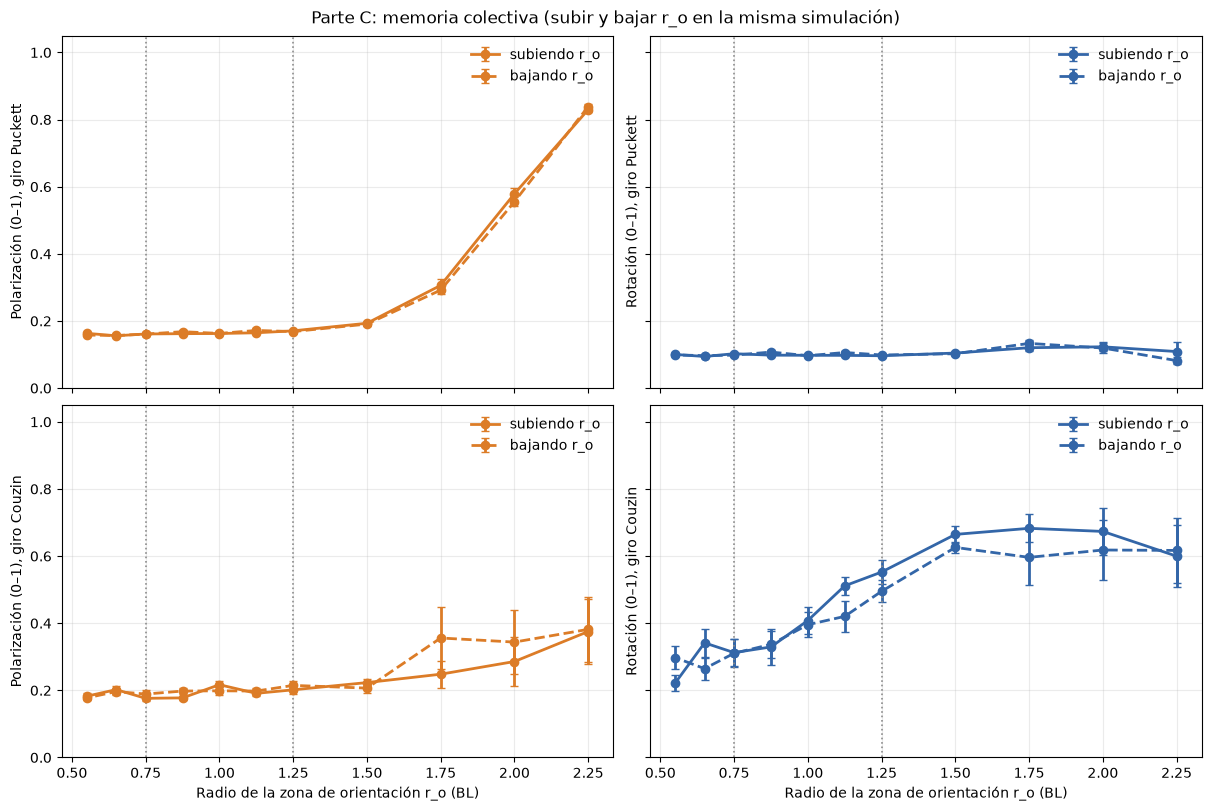

In [24]:
FIGURE_C4_TITLE = "Parte C: memoria colectiva (subir y bajar r_o en la misma simulación)"

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True, constrained_layout=True)
rows_of_panels = [(memory_summary, "giro Puckett"), (slow_memory_summary, "giro Couzin")]
for row_index in range(2):
    summary, turn_name = rows_of_panels[row_index]
    for axis, column, axis_label, color in [(axes[row_index, 0], "polarization", "Polarización (0–1)", PUCKETT_COLOR),
                                            (axes[row_index, 1], "rotation", "Rotación (0–1)", A0_COLOR)]:
        for direction, line_style in [("subiendo", "-"), ("bajando", "--")]:
            rows = summary.loc[direction]
            axis.errorbar(rows.index, rows[(column, "mean")], yerr=rows[(column, "sem")],
                          color=color, linestyle=line_style, marker="o", markersize=6, linewidth=2, capsize=3,
                          label=f"{direction} r_o")
        for radius in [0.75, 1.25]:
            axis.axvline(radius, color="0.55", linestyle=":", linewidth=1.2)
        axis.set_ylabel(f"{axis_label}, {turn_name}")
        axis.set_ylim(0, 1.05)
        axis.grid(alpha=0.25)
        axis.legend(frameon=False)
axes[1, 0].set_xlabel("Radio de la zona de orientación r_o (BL)")
axes[1, 1].set_xlabel("Radio de la zona de orientación r_o (BL)")
fig.suptitle(FIGURE_C4_TITLE)
fig.savefig(FIGURE_FOLDER / "part_c_memory.png", dpi=150)
plt.show()

## Guardar todos los resultados juntos

Unimos las tres partes en `data/results.csv` (una fila por simulación, con una columna `part`).

In [25]:
ladder_results["part"] = "A"
groups_results["part"] = "B"
couzin_results["part"] = "C"
slow_results["part"] = "C extra (giro lento)"
all_results = pd.concat([ladder_results, groups_results, couzin_results, slow_results], ignore_index=True)
all_results.to_csv(DATA_FOLDER / "results.csv", index=False)
print(len(all_results), "simulations saved in data/results.csv")

370 simulations saved in data/results.csv


## Conclusión

Ver las secciones "Resultados" y "Conclusión" del [README](README.md) de este estudio.